In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
from sklearn.metrics import (
    roc_auc_score, classification_report,
    ConfusionMatrixDisplay, confusion_matrix, RocCurveDisplay
)

In [2]:
# 1. Load data
df = pd.read_csv("../data/clean/user_features.csv")

X = df.drop(columns=["user_id", "is_churn"])
y = df["is_churn"].astype(int)


In [3]:
# 2. Preprocessing
num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()

preprocessor = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num_cols),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), cat_cols)
])

In [4]:
# 3. Cross-validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

results = []

for depth in range(1, 6):
    model = Pipeline([
        ("prep", preprocessor),
        ("tree", DecisionTreeClassifier(
            max_depth=depth,
            min_samples_leaf=10,
            random_state=42
        ))
    ])

    scores = cross_validate(
        model, X, y, cv=cv,
        scoring=["roc_auc", "accuracy", "precision", "recall"]
    )

    results.append({
        "max_depth": depth,
        "AUC": scores["test_roc_auc"].mean(),
        "AUC_std": scores["test_roc_auc"].std(),
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean()
    })

results = pd.DataFrame(results)
print("\n=== Perbandingan Kedalaman Pohon ===")
print(results.round(3).to_string(index=False))

best_depth = int(results.loc[results["AUC"].idxmax(), "max_depth"])
print(f"\nKedalaman terpilih: {best_depth}")


=== Perbandingan Kedalaman Pohon ===
 max_depth   AUC  AUC_std  Accuracy  Precision  Recall
         1 0.632    0.077     0.740      0.612   0.366
         2 0.607    0.088     0.720      0.585   0.231
         3 0.615    0.093     0.700      0.603   0.245
         4 0.596    0.108     0.716      0.639   0.258
         5 0.608    0.103     0.704      0.503   0.258

Kedalaman terpilih: 1


In [5]:
# 4. Out-of-fold evaluation
model = Pipeline([
    ("prep", preprocessor),
    ("tree", DecisionTreeClassifier(
        max_depth=best_depth,
        min_samples_leaf=10,
        random_state=42
    ))
])

proba = cross_val_predict(
    model, X, y, cv=cv, method="predict_proba"
)[:, 1]

pred = (proba >= 0.5).astype(int)

print(f"\nOOF ROC-AUC: {roc_auc_score(y, proba):.3f}")
print("\n=== Classification Report ===")
print(classification_report(y, pred, zero_division=0))


OOF ROC-AUC: 0.596

=== Classification Report ===
              precision    recall  f1-score   support

           0       0.77      0.90      0.83       176
           1       0.60      0.36      0.45        74

    accuracy                           0.74       250
   macro avg       0.69      0.63      0.64       250
weighted avg       0.72      0.74      0.72       250



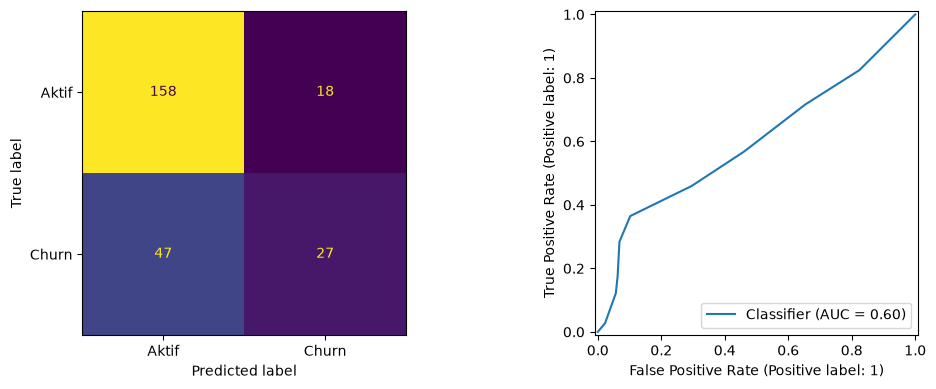

In [6]:
# 5. Visualisasi evaluasi
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

ConfusionMatrixDisplay(
    confusion_matrix(y, pred),
    display_labels=["Aktif", "Churn"]
).plot(ax=axes[0], colorbar=False)

RocCurveDisplay.from_predictions(y, proba, ax=axes[1])

plt.tight_layout()
plt.show()


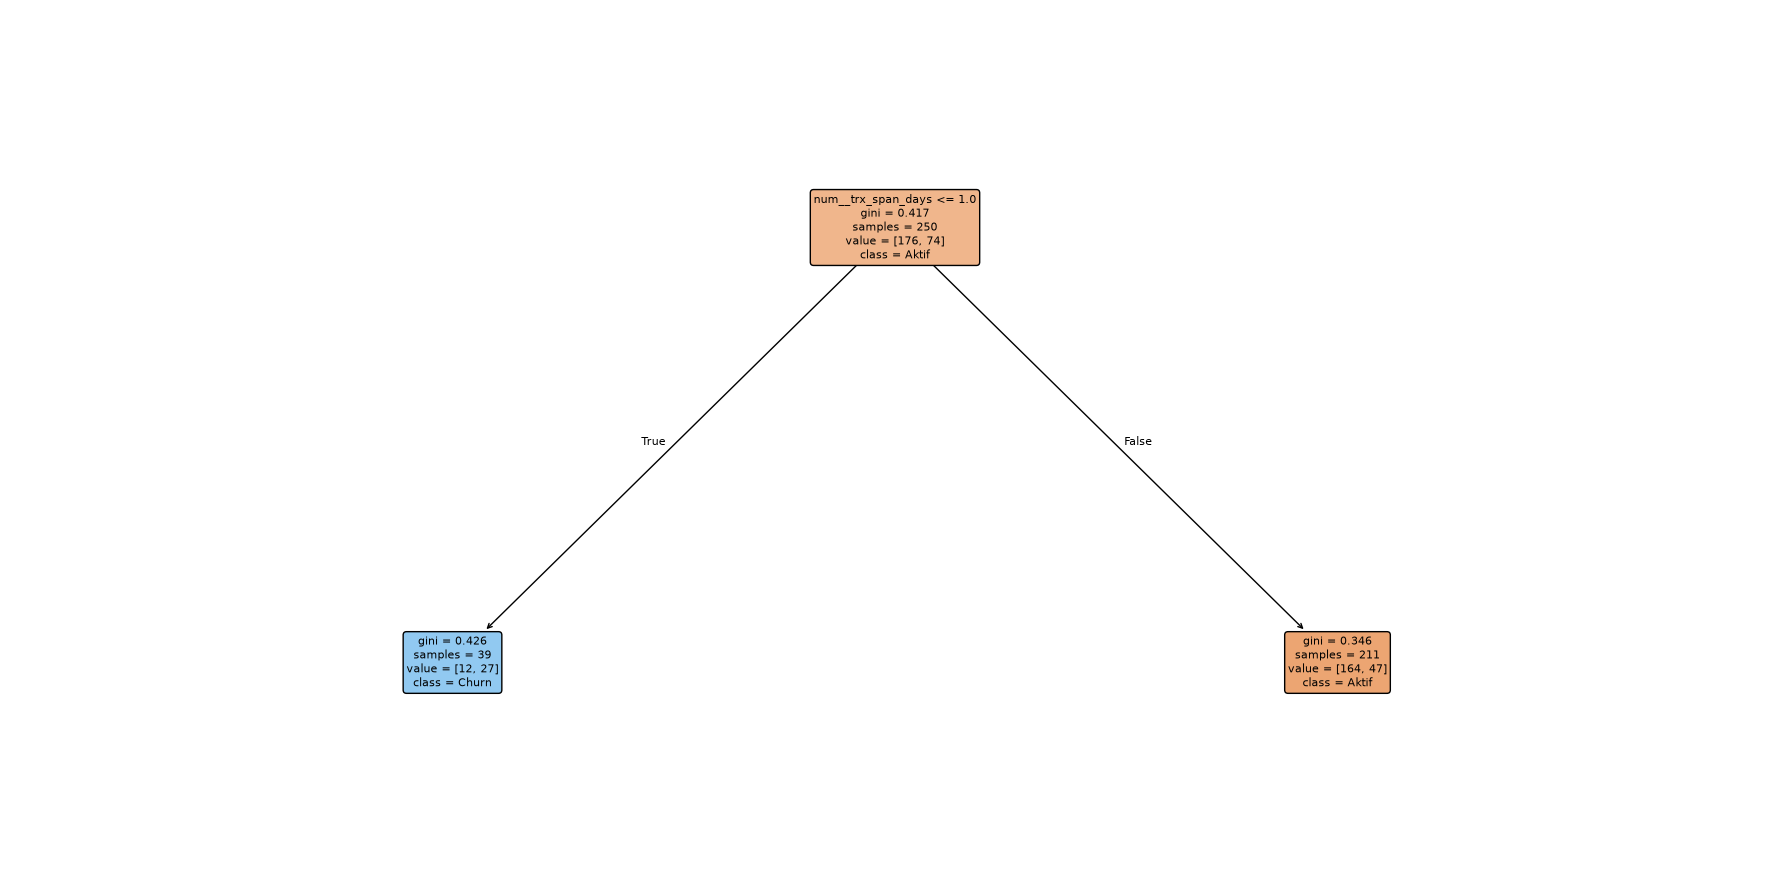

In [7]:
# 6. Fit final tree untuk interpretasi
model.fit(X, y)

feature_names = model.named_steps["prep"].get_feature_names_out()
tree = model.named_steps["tree"]

plt.figure(figsize=(18, 9))
plot_tree(
    tree,
    feature_names=feature_names,
    class_names=["Aktif", "Churn"],
    filled=True,
    rounded=True,
    fontsize=8
)
plt.tight_layout()
plt.show()

In [9]:
# 7. Feature importance
importance = pd.Series(
    tree.feature_importances_,
    index=feature_names
).sort_values(ascending=False)

print("\n=== Feature Importance ===")
print(importance[importance <= 1].round(3))


=== Feature Importance ===
num__trx_span_days                    1.0
num__tenure_days                      0.0
num__n_trx                            0.0
num__total_amount                     0.0
num__age                              0.0
num__avg_amount                       0.0
num__trx_recency_days                 0.0
num__total_sessions                   0.0
num__active_days                      0.0
num__recency_days                     0.0
num__pct_browse                       0.0
num__pct_loan_apply                   0.0
num__pct_payment                      0.0
num__pct_promo_click                  0.0
cat__acquisition_channel_Ads          0.0
cat__acquisition_channel_Affiliate    0.0
cat__acquisition_channel_Organic      0.0
cat__acquisition_channel_Referral     0.0
cat__city_Bandung                     0.0
cat__city_Jakarta                     0.0
cat__city_Surabaya                    0.0
dtype: float64
